In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from numba import jit

In [9]:
#@jit
def hazards(y,c_idx,num_reax,N,y_totp,y_tot,beta,gamma,sigma,max_size):
    a =np.zeros(num_reax)                                     #reaction hazards 
    v=np.zeros([num_reax,max_size])                           #reaction vectors    
    a[0]=(k_tr*y_totp)/(1+K*y_tot/(s0*n))**n
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1

    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -2
                else:
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                v[i,int(np.sum(species_idx[:,i]))] = 1
            else:                            #plasmid shedding         
                v[i,0] = 1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])-1] = 1   
    return a,v
    
#@jit
def ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    #for i in np.arange(2,len(y)):
    #    y_tot1+=i*y[i]
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    
    while t_y<tau:
        ############################### pole 1 ##################################
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
        y1[0] = dummy
        N1 = len(c_idx1)                                            #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
        a1,v1 = hazards(y1,c_idx1,num_reax1,N1,y_tot1,y_tot,beta,gamma,sigma,max_size)

        
        ############################### pole 2 ##################################
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
        a2,v2 = hazards(y2,c_idx2,num_reax2,N2,y_tot2,y_tot,beta,gamma,sigma,max_size)

        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        sum_a=np.sum(a)
        cumsum_a=np.cumsum(a,axis=0)
        epsilon=np.random.uniform(0,1,2)
        j=np.min(np.where(epsilon[0]*sum_a<cumsum_a)) 
        t_f=(np.log(1/epsilon[1]))/sum_a
                     
        if t_y+t_f<tau:  

            t_y+=t_f 
            if (j==num_reax1+num_reax2):
                y2[0]+=1
                y1[0]-=1
            elif (j==num_reax1+num_reax2+1):
                y2[0]-=1
                y1[0]+=1
            elif (num_reax1<=j and j<num_reax1+num_reax2):
                y2+=v2[j-num_reax1,:]  
            else:
                y1+=v1[j,:]    
                
            y1[0]+=y1[1]
            y2[0]+=y2[1]
            y1[1]=y1[0]
            y2[1]=y2[0]
            y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
            y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
            y_tot = y_tot1+y_tot2
            y1[1]=0
            y2[1]=0
            
            if (j==0 or j==num_reax1):
                x= np.append(x,y_tot)
                t_x =np.append(t_x,[t_y])
        else:
            t_y=tau
            x=np.append(x,x[-1])
            t_x =np.append(t_x,[t_y])  
    y = np.append(y1,y2,axis=0)
    #print(y_tot,x[-1])
    return y,x,t_y,t_x

#@jit
def single_lineage(x0,gen,tau,cluster,thresh,beta,gamma,sigma,max_size):
    x=[x0]
    t=[0]
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    cluster_num = np.zeros(gen)
    ratio = np.zeros([gen,2])  #ratio = [parent,inheritance]
    count=0
    z=np.zeros(max_size*2)   #keep track of n-cluster numbers
    loss=0
    for i in range(gen):
        if x0>0:
            count+=1
            yy,xx,tty,ttx=ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma,max_size)
            y0 = np.zeros(2*max_size)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
                y0[0]=x0
            else:
                x=np.append(x,xx)
                t=np.append(t,t[-1]+ttx)
                pole = np.random.uniform(0,1)
                if pole<0.5:
                    y0[:max_size]=yy[:max_size]
                    tracker = 1
                else:
                    y0[:max_size]=yy[max_size:]
                    tracker = 2
                y0[1]=y0[0]
                x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
                if i%100 == 0:
                    print(i,x0)
                if x0 == 0 or x0 == xx[-1]:
                    loss+=1
                #################### just to continue with simulation, choose other cell ##############
                #################### remove entire "if block" if plasmid loss is to be tracked ########################## 
                if x0 == 0:  
                    print('plasmid loss') #there may be other instances of loss, this only tracks those which were detected by being selected 
                    y0 = np.zeros(2*max_size)
                    if tracker == 1:
                        y0[:max_size]=yy[max_size:]
                    else:
                        y0[:max_size]=yy[:max_size]
                    y0[1]=y0[0]
                    x0=xx[-1]
                    #x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
                    #print(i,x0)
                y0[1]=0     
            ratio[i,:]=[xx[-1],x0/xx[-1]]
            z+=yy
        cluster_num[i] = np.sum(yy[thresh:max_size])+np.sum(yy[max_size+thresh:]) 
    print('loss=',loss)
    return x,t,ratio[:count,:],cluster_num[:count],z


def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[0,0].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[0,0].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[0,0].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[0,0].set_ylim([0,max(x)+1])
    axes[0,0].set_xlim([0,gen*tau])
    axes[0,0].set_xlabel('Time (min)')
    axes[0,0].set_ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [19]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=500
beta = 0.1 #plasmid recruitment rate constant
gamma = 1*beta #plasmid combination rate constant
sigma= 1*beta  #plasmid dissociation rate constant
rho = 0.1  #plasmid transfer rate constant

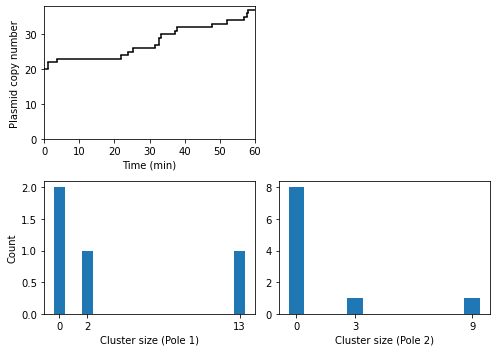

In [23]:
gen=1
y0 = np.zeros(2*max_size)
y0[0]=x0
f,axes = plt.subplots(2,2,figsize=(7,5))
y,x,t_y,t_x = ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma,max_size)
plot_stairs(x,t_x)
y1 = y[:max_size]
y2 = y[max_size:]

axes[0,1].axis('off')
axes[1,0].bar(range(np.max(np.where(y1>0))+1),y1[:np.max(np.where(y1>0))+1])
axes[1,0].set_xticks(np.where(y1>0)[0])
axes[1,1].bar(range(np.max(np.where(y2>0))+1),y2[:np.max(np.where(y2>0))+1])
axes[1,1].set_xticks(np.where(y2>0)[0])
for i in range(2):
    axes[1,i].set_xlabel('Cluster size (Pole %d)' %(i+1) )
axes[1,0].set_ylabel('Count')
plt.tight_layout()
plt.show()

What is a cluster? What is the threshold size for a group to be called a cluster?
We can keep track of the distribution of number of clusters in a lineage.



0 4.0
100 35.0
200 23.0
300 38.0
400 8.0
500 27.0
600 32.0
700 19.0
800 13.0
900 6.0
loss= 0


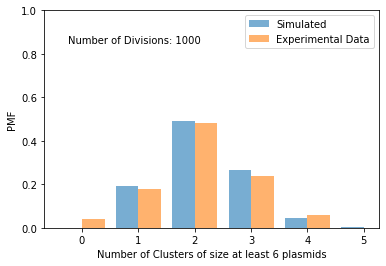

0 cluster: 0.001
1 cluster: 0.191
2 cluster: 0.493
3 cluster: 0.268
4 cluster: 0.045
5 cluster: 0.002


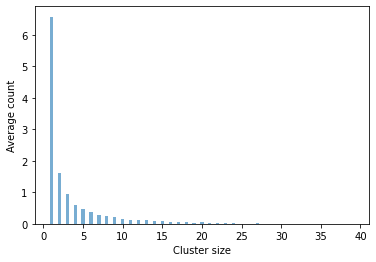

41.403


In [16]:
c_thresh = 6
cluster = True
gen=1000
x,t,ratio,c_num,z=single_lineage(x0,gen,tau,cluster,c_thresh,beta,gamma,sigma,max_size)
heights = np.bincount(c_num.astype(int))/len(c_num)
bars = plt.bar(np.arange(len(heights))-0.2,heights,width=0.4,color='C0',alpha=0.6,label='Simulated') 
plt.text(-0.25,0.85,'Number of Divisions: %d' %len(c_num))
plt.bar(np.arange(5)+0.2,[0.04,0.18,0.48,0.24,0.06],width=0.4,color='C1',alpha=0.6,label='Experimental Data')
plt.ylim([0,1])
plt.xticks(range(len(heights)))
plt.xlabel('Number of Clusters of size at least %d plasmids' %(c_thresh))
plt.ylabel('PMF')
plt.legend()
plt.show()

for i in range(len(heights)):
    print('%d cluster:' %(i),heights[i])
    
z1=z[:max_size]
z2=z[max_size:]
z_st = z1+z2
f = plt.figure()
last = np.max(np.where(z_st>0)[0])
z_st[1]=z_st[0]
bars = plt.bar(np.arange(1,last+1),z_st[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.show()
print(np.dot(np.arange(1,last+1),(z_st[1:last+1]/len(c_num))))

z1=z[:max_size]
z2=z[max_size:]
z_st = z1+z2
f = plt.figure()
last = np.max(np.where(z_st>0)[0])
z_st[1]=z_st[0]
bars = plt.bar(np.arange(1,last+1),z_st[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlim(0,30)
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.show()
print(np.dot(np.arange(1,last+1),(z_st[1:last+1]/len(c_num))))

In [17]:
cluster=[False,True]
gen=1000
c_thresh = 6
#f = plt.figure()
for j in range(2):
    x,t,ratio1,c_num,z=single_lineage(x0,gen,tau,cluster[j],c_thresh,beta,gamma,sigma,max_size)
    ratio2 = np.zeros([len(ratio1),2])
    ratio2[:,0] = ratio1[:,0]
    ratio2[:,1] = 1-ratio1[:,1]
    ratio = np.append(ratio1,ratio2,axis=0)
    #sns.jointplot(ratio[:,0],ratio[:,1])
    if cluster[j]==True:
        ratio_c = ratio
    else:
        ratio_uc = ratio

loss= 0
0 20.0
100 16.0
200 16.0
300 21.0
400 31.0
500 34.0
600 19.0
700 10.0
800 12.0
900 10.0
loss= 0


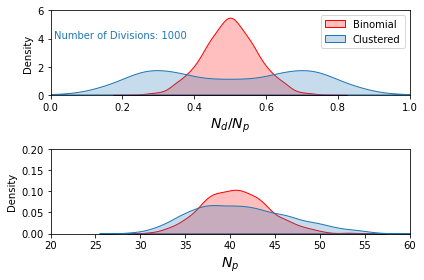

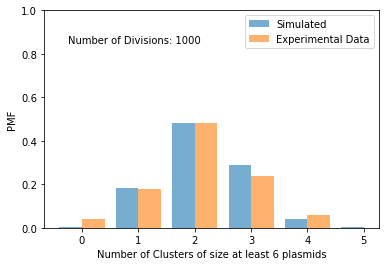

0 cluster: 0.002
1 cluster: 0.183
2 cluster: 0.48
3 cluster: 0.291
4 cluster: 0.04
5 cluster: 0.004


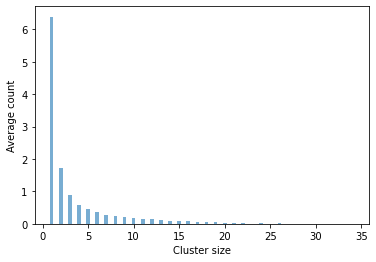

41.332


In [18]:
f,axes=plt.subplots(2,1)
sns.kdeplot(ratio_uc[:,1],label='Binomial',shade=True,ax=axes[0],color='r')
sns.kdeplot(ratio_c[:,1],label='Clustered',shade=True,ax=axes[0],color='C0')
axes[0].set_xlabel(r'$N_d/N_p$',fontsize=14)
axes[0].text(0.01,4,'Number of Divisions: %d' %(int(len(ratio_c)/2)), color='C0')
axes[0].set_ylim([0,6])
axes[0].set_xlim([0,1])
axes[0].legend()

sns.kdeplot(ratio_uc[:,0],label='Binomial',shade=True,ax=axes[1],color='r')
sns.kdeplot(ratio_c[:,0],label='Clustered',shade=True,ax=axes[1],color='C0')
axes[1].set_xlabel(r'$N_p$',fontsize=14)
axes[1].set_ylim([0,0.2])
axes[1].set_xlim([20,60])
plt.tight_layout()
plt.show()

heights = np.bincount(c_num.astype(int))/len(c_num)
bars = plt.bar(np.arange(len(heights))-0.2,heights,width=0.4,color='C0',alpha=0.6,label='Simulated') 
plt.text(-0.25,0.85,'Number of Divisions: %d' %len(c_num))
plt.bar(np.arange(5)+0.2,[0.04,0.18,0.48,0.24,0.06],width=0.4,color='C1',alpha=0.6,label='Experimental Data')
plt.ylim([0,1])
plt.xticks(range(len(heights)))
plt.xlabel('Number of Clusters of size at least %d plasmids' %(c_thresh))
plt.ylabel('PMF')
plt.legend()
plt.show()

for i in range(len(heights)):
    print('%d cluster:' %(i),heights[i])
    
z1=z[:max_size]
z2=z[max_size:]
z_st = z1+z2
f = plt.figure()
last = np.max(np.where(z_st>0)[0])
z_st[1]=z_st[0]
bars = plt.bar(np.arange(1,last+1),z_st[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.show()
print(np.dot(np.arange(1,last+1),(z_st[1:last+1]/len(c_num))))

In [ ]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=500
beta = 0.1 #plasmid recruitment rate constant
gamma = 1*beta #plasmid combination rate constant
sigma= 1*beta  #plasmid dissociation rate constant
rho = 0.1  #plasmid transfer rate constant

gen=10
y0 = np.zeros(2*max_size)
y0[0]=x0
f,axes = plt.subplots(2,2,figsize=(7,5))
for i in range(gen):
    y,x,t_y,t_x = ssa_hyperbolic(y0,x0,tau,beta,gamma,sigma,max_size)
    y0 = np.zeros(2*max_size)
    pole = np.random.uniform(0,1)
    if pole<0.5:
        y0[:max_size]=y[:max_size]
    else:
        y0[:max_size]=y[max_size:]
        x0=0
        y0[1]=y0[0]
        for k in np.arange(1,len(y0)):
            x0+=k*y0[k]
        y0[1]=0
gen=1
plot_stairs(x,t_x)
y1 = y[:max_size]
y2 = y[max_size:]
axes[0,1].axis('off')
axes[1,0].bar(range(np.max(np.where(y1>0))+1),y1[:np.max(np.where(y1>0))+1])
axes[1,0].set_xticks(np.where(y1>0)[0])
axes[1,1].bar(range(np.max(np.where(y2>0))+1),y2[:np.max(np.where(y2>0))+1])
axes[1,1].set_xticks(np.where(y2>0)[0])
for i in range(2):
    axes[1,i].set_xlabel('Cluster size (Pole %d)' %(i+1) )
    axes[1,i].set_xlim([0,max(np.max(np.where(y2>0))+1,np.max(np.where(y1>0))+1)])
    axes[1,i].set_ylim([0,max(max(y2),max(y1))+1])
axes[1,0].set_ylabel('Count')
plt.tight_layout()
plt.show()

In [ ]:
repeats = 5
gen=5
cluster=True
f,axes = plt.subplots(1,repeats,figsize=(10,3))
for i in range(repeats):
    x,t,_,__=single_lineage(x0,gen,tau,cluster,0,beta,gamma,sigma)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()

In [ ]:
from scipy.io import loadmat

def plot_cmap(array,c,rho):
    for i in range(len(c)-1):
        axes[i].scatter(array[:,1]/array[:,0],array[:,2]/array[:,0],c=array[:,c[i]],cmap='viridis',s=80,vmin=0,vmax=0.75)  
    im =  axes[len(c)-1].scatter(array[:,1]/array[:,0],array[:,2]/array[:,0],c=array[:,-1],cmap='viridis',s=80,vmin=0,vmax=0.75) 
    for i in range(len(c)):
        axes[i].set_title(r'$C=$%d' %(c[i]-3))
        axes[i].set_xlabel(r'$\gamma/\beta$')
        axes[i].set_ylabel(r'$\sigma/\beta$')
    
    plt.suptitle(r'Probability of having C clusters before division ($\rho =$ %1.2f, $\beta$ =%1.3f)' %(rho,array[0,0] ),y=1.1)
    
    plt.tight_layout()
    cbar_ax = f.add_axes([1, 0.25, 0.025, 0.6])
    f.colorbar(im, cax=cbar_ax)
    plt.show()
    return None
    


In [ ]:
sig01=loadmat('loc001.mat',squeeze_me=True)
beta01=sig01['beta01']   #[***[0] beta ***[1] gamma ***[2] sigma ***[3] 0-c ***[4] 1-c ***[5] 2-c ***[6] 3-c ***[7] 4-c]
beta001=sig01['beta001']   
beta0001=sig01['beta0001'] 

c=[3,4,5,6]  #c[i]-3 clusters so this is [0,1,2,3]-clusters
rho = 0.1
f,axes = plt.subplots(1,len(c),figsize=(7,2.5))
plot_cmap(beta01,c,rho) 

f,axes = plt.subplots(1,len(c),figsize=(7,2.5))
plot_cmap(beta001,c,rho) 

f,axes = plt.subplots(1,len(c),figsize=(7,2.5))
plot_cmap(beta0001,c,rho)
                           